# Explore hash frequency => coverage in species.x.metagenome intersections

In [2]:
import sourmash
from sourmash.save_load import SaveSignaturesToLocation
import collections
import math
import polars as pl
import matplotlib.pyplot as plt

In [3]:
CORE_SPECIES=set([ x.strip() for x in open('../inputs.branchwater/names.list') ])

In [4]:
df = (
    pl.scan_parquet('../outputs.cds3/pq/mag+gtdb.cds3.x.3216.manysearch.parquet')
    .filter(pl.col('intersect_hashes') >= 3)
    .with_columns(species_name=pl.col('query_name').str.split(' ').list.slice(1, 2).list.join( " "))
    .filter(pl.col('species_name').is_in(CORE_SPECIES))
).collect()

In [5]:
species = 's__Lactobacillus amylovorus'

In [6]:
lacto_df = df.filter(pl.col('species_name') == species)

In [8]:
lacto_df

query_name,query_md5,match_name,containment,intersect_hashes,ksize,scaled,moltype,match_md5,jaccard,max_containment,average_abund,median_abund,std_abund,query_containment_ani,match_containment_ani,average_containment_ani,max_containment_ani,n_weighted_found,total_weighted_hashes,species_name
str,str,str,f64,i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,str
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR11183330""",0.012438,58,21,1000,"""DNA""","""91703afddeec80707490192525488c…",0.000223,0.012438,3.396552,1.0,5.394568,0.811474,0.670624,0.741049,0.811474,197,1066419,"""s__Lactobacillus amylovorus"""
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR11125500""",0.05876,274,21,1000,"""DNA""","""0f859a6a6982ea1429c0cd88f5a3c3…",0.000741,0.05876,8.908759,3.0,21.254859,0.873746,0.709886,0.791816,0.873746,2441,909916,"""s__Lactobacillus amylovorus"""
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR11124837""",0.085353,398,21,1000,"""DNA""","""df16d2720cf46f2cbdcd736baf79eb…",0.001061,0.085353,25.41206,4.0,30.519638,0.889417,0.722113,0.805765,0.889417,10114,957945,"""s__Lactobacillus amylovorus"""
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR11124703""",0.04718,220,21,1000,"""DNA""","""a6320b5bbed19134565879332a44ab…",0.00062,0.04718,3.427273,2.0,3.320622,0.86466,0.703922,0.784291,0.86466,754,1046330,"""s__Lactobacillus amylovorus"""
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR11126418""",0.06305,294,21,1000,"""DNA""","""6b9ed8fbc3e3c6ff8cd26bc00bfbeb…",0.000712,0.06305,31.452381,31.0,28.494231,0.876682,0.708521,0.792601,0.876682,9247,900747,"""s__Lactobacillus amylovorus"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR8960533""",0.106584,497,21,1000,"""DNA""","""61fe0def0d6d2de389f8503840f355…",0.000406,0.106584,8.627767,3.0,11.595126,0.898876,0.689536,0.794206,0.898876,4288,4195201,"""s__Lactobacillus amylovorus"""
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR8960516""",0.087712,409,21,1000,"""DNA""","""1ca886a16667ea744764a7b38e7e46…",0.000272,0.087712,6.753056,3.0,11.446063,0.890573,0.676532,0.783552,0.890573,2762,5122204,"""s__Lactobacillus amylovorus"""
"""GCF_028308525 s__Lactobacillus…","""051c672def122e4ccf47573cfda2df…","""SRR8960428""",0.090929,424,21,1000,"""DNA""","""b15a58764da08f6ea7279f8a0c0432…",0.00026,0.090929,98.792453,8.0,133.651809,0.892102,0.67511,0.783606,0.892102,41888,8367756,"""s__Lactobacillus amylovorus"""


(0.0, 50000.0)

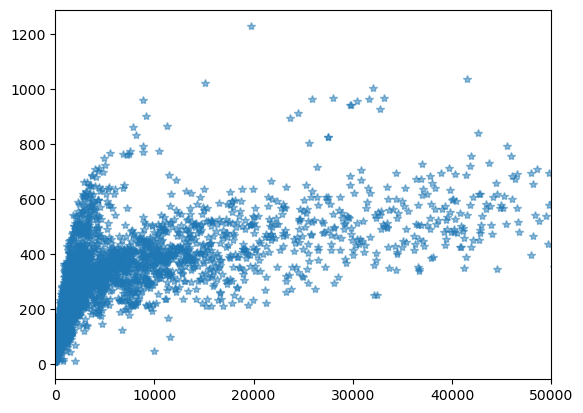

In [11]:
plt.plot(lacto_df['n_weighted_found'], lacto_df['intersect_hashes'], '*', alpha=0.5)
plt.xlim(0, 50000)

## Load and calculate species hash utilization

In [3]:
LOCATION='../outputs.isect/3216_isect.collect.d/{species}.collected.sig.zip'

def calc_hash_utilization(species):
    total = 0
    dd = collections.defaultdict(int)
    for ss in sourmash.load_file_as_signatures(LOCATION.format(species=species)):
        total += 1
        for hashval in ss.minhash.hashes:
            dd[hashval] += 1

    # build list => dataframe
    xx = []
    for k, v in dd.items():
        xx.append(dict(hashval=k, count=v, freq=v/total))

    # convert to dataframe, sort by frequency descending, add rank column
    df = pl.DataFrame(xx).sort('freq', descending=True).with_row_index(name='rank')

    return df

SPECIES='s__Lactobacillus amylovorus'
calc_hash_utilization(SPECIES)

rank,hashval,count,freq
u32,i64,i64,f64
0,9051771093072211,2648,0.823383
1,17959031327481003,2647,0.823072
2,6953431835453339,2635,0.819341
3,9935867230983810,2632,0.818408
4,7064433461156742,2628,0.817164
…,…,…,…
4418,5364036848528580,1,0.000311
4419,12877118389652717,1,0.000311
4420,5475045417496885,1,0.000311


## Load 'em all

In [4]:
species_hash_dd = {}
for species in CORE_SPECIES:
    df = calc_hash_utilization(species)
    species_hash_dd[species] = df


## Plot

In [5]:
def plot_hash_rank(species, species_hash_df, cutoff, *, show=True):
    plt.plot(species_hash_df['rank'], species_hash_df['freq'])
    p10 = species_hash_df.filter(pl.col('freq') > 0.10).tail(1)['rank'].item()
    pmax = species_hash_df.head(1)['freq'].item()
    plt.axhline(pmax, linestyle='--', color='green', label='max freq')
    plt.axhline(0.10, linestyle='--', color='red', label='cutoff')
    plt.axvline(cutoff, linestyle='--', color='blue', label=f'rank cutoff={cutoff}')
    plt.xlim(0, p10)
    plt.ylim(0, 1)
    plt.ylabel('fraction of metagenomes')
    plt.xlabel('rank-order')
    plt.title(f"{species} hash utilization across pig panmetagenome")
    plt.legend(loc='center right')
    if show:
        plt.show()

In [6]:
rank_cutoff = {'s__Bariatricus sp004560705': 500,
 's__Colivicinus sp002299675': 750,
 's__Cryptobacteroides sp000432655': 700,
 's__Cryptobacteroides sp000434935': 600,
 's__Cryptobacteroides sp034089285': 250,
 's__Cryptobacteroides sp900546925': 750,
 's__Fimisoma sp002320005': 650,
 's__Floccifex porci': 650,
 's__JAFBIX01 sp021531895': 600,
 's__Lactobacillus amylovorus': 110,
 's__Mogibacterium_A kristiansenii': 225,
 's__Ornithospirochaeta sp022785155': 1000,
 's__Prevotella sp000434975': 400,
 's__Prevotella sp002251295': 800,
 's__Sodaliphilus sp004557565': 750,
 's__UBA2868 sp004552595': 750}

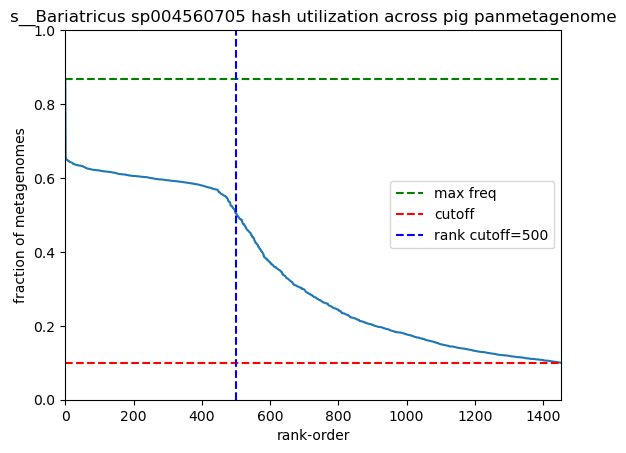

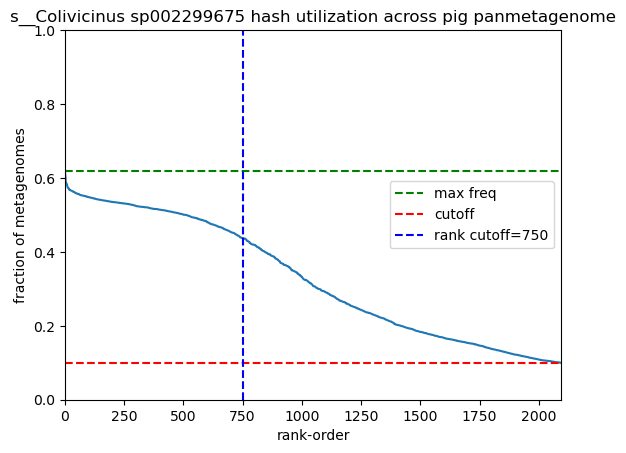

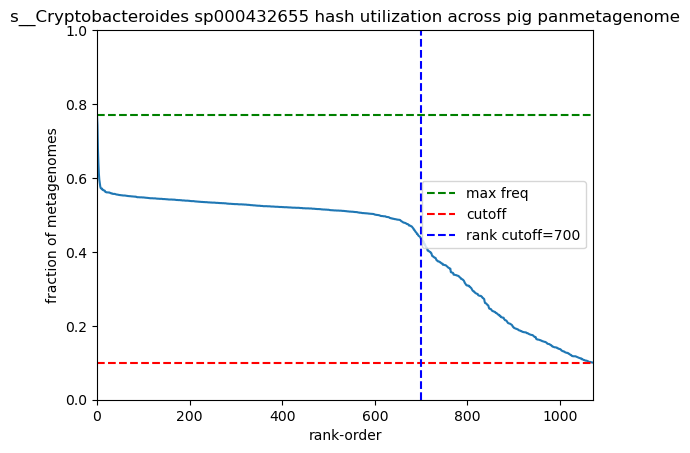

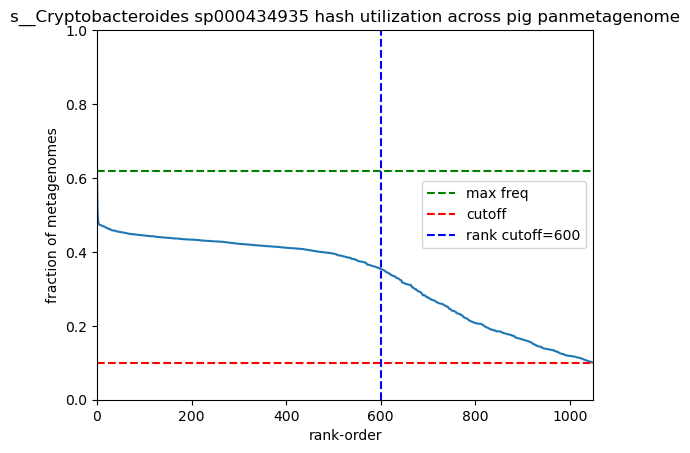

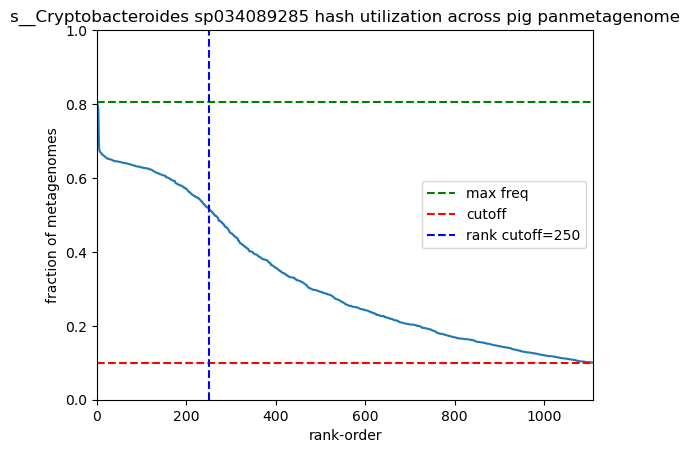

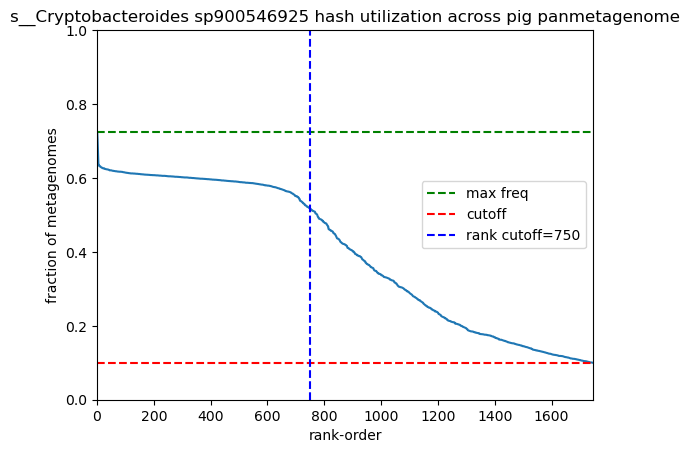

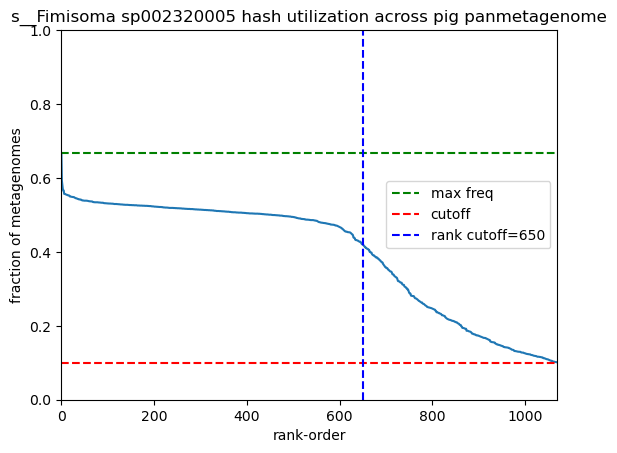

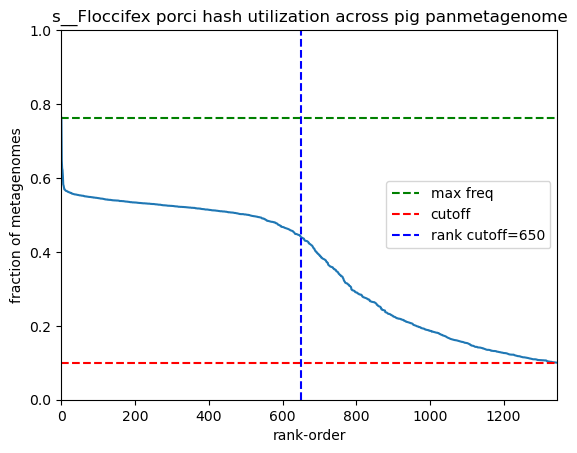

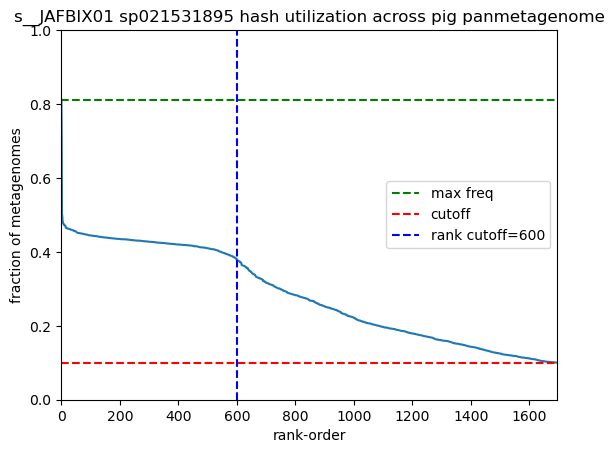

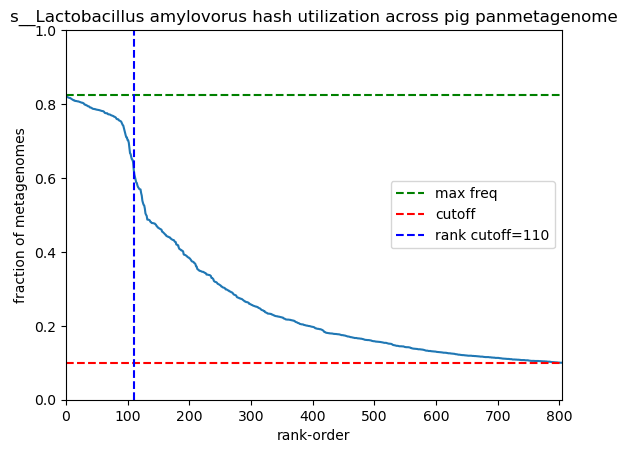

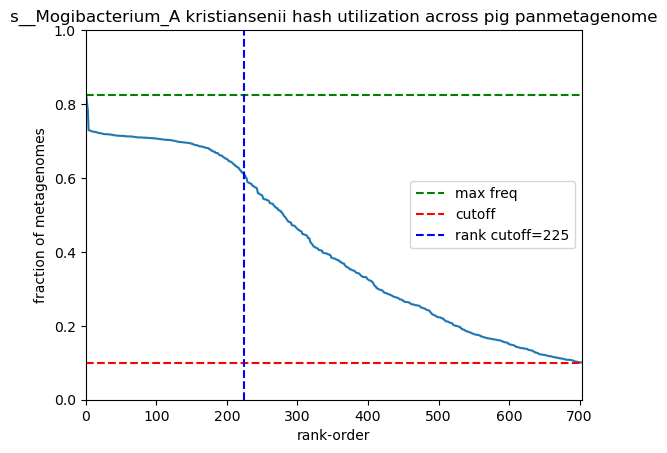

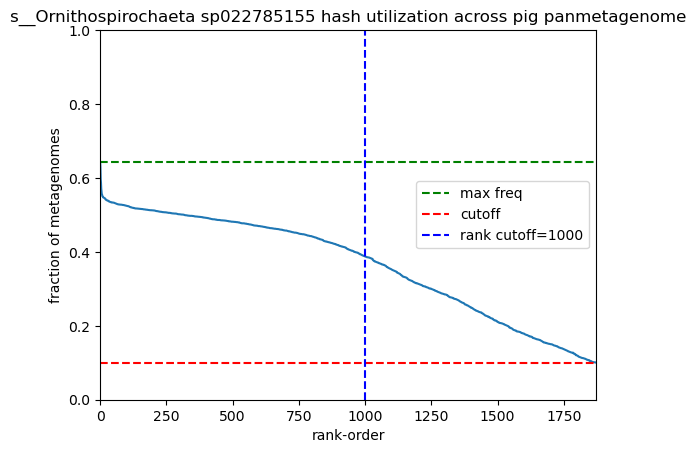

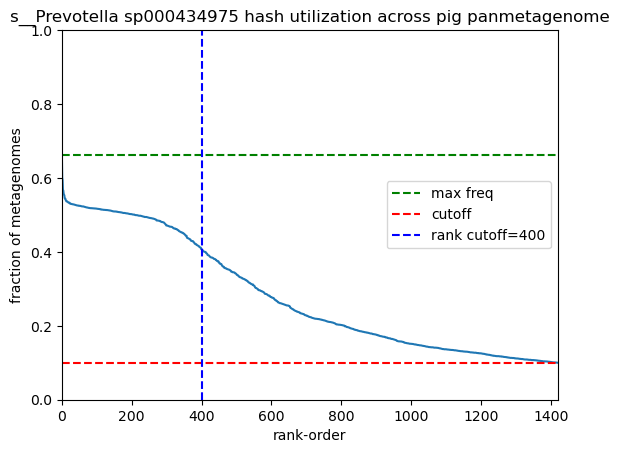

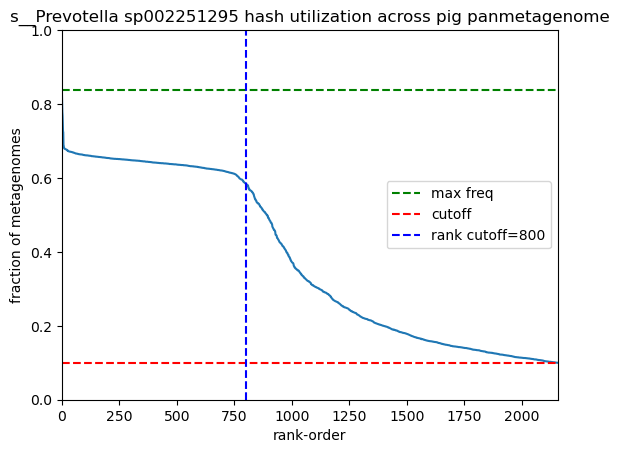

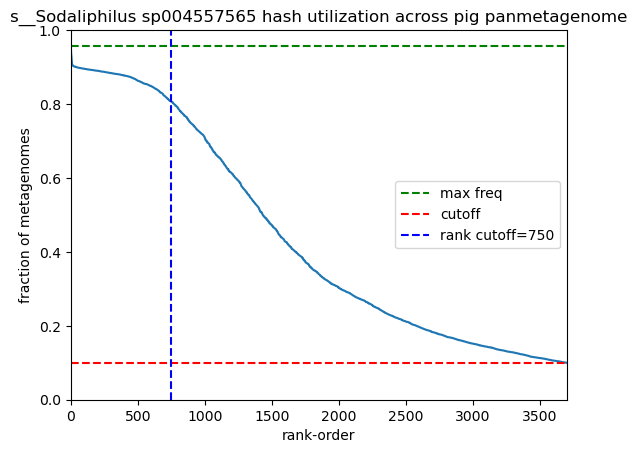

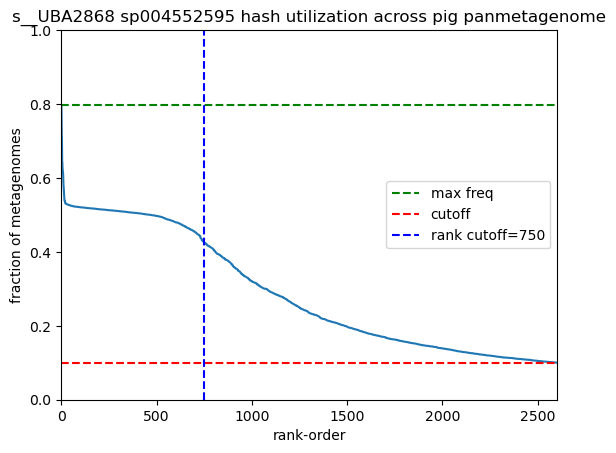

In [7]:
for species in CORE_SPECIES:
    df = species_hash_dd[species]
    cutoff = rank_cutoff[species]
    plot_hash_rank(species, df, cutoff, show=True)
    #plt.savefig(f'hashutil.{species}.png')
    #plt.clf()

## Make three sketches for each - one at defined cutoff, one at 10%, and one complete.

In [8]:
blank_mh = sourmash.MinHash(n=0, ksize=21, scaled=1000, track_abundance=False)

with SaveSignaturesToLocation('../species-tophash2.sig.zip') as save_sig:
    for species in CORE_SPECIES:
        orig_df = species_hash_dd[species]
        cutoff = rank_cutoff[species]

        # first: no cutoff (control ;)
        mh = blank_mh.copy_and_clear()
        for hashval in orig_df['hashval']:
            mh.add_hash(hashval)
        ss = sourmash.SourmashSignature(mh, name=f"{species} cds3-entire")
        save_sig.add(ss)

        # second: tophash cutoff
        mh = blank_mh.copy_and_clear()
        df = orig_df.filter(pl.col('freq') > 0.1)
        for hashval in df['hashval']:
            mh.add_hash(hashval)
        ss = sourmash.SourmashSignature(mh, name=f"{species} tophash freq>0.1")
        save_sig.add(ss)

        # last: tophash cutoff
        mh = blank_mh.copy_and_clear()
        df = orig_df.filter(pl.col('rank') < cutoff)
        for hashval in df['hashval']:
            mh.add_hash(hashval)
        ss = sourmash.SourmashSignature(mh, name=f"{species} tophash cutoff={cutoff}")
        save_sig.add(ss)

        
        

## Load species CDS3

just some example code for now

In [88]:
cds3_filename=f'../inputs.branchwater/queries/{SPECIES}.cds3.sig.zip'
species_sig = list(sourmash.load_file_as_signatures(cds3_filename))[0]
len(species_sig.minhash)

4663

## Load/explore manysearch results

In [9]:
manysearch_df = (
    pl.read_csv('../species-tophash2.x.3216.manysearch.csv')
)

In [12]:
manysearch_entire_df = manysearch_df.filter(pl.col('query_name').str.contains('cds3-entire'))
manysearch_freq_df = manysearch_df.filter(pl.col('query_name').str.contains('freq'))
manysearch_cutoff_df = manysearch_df.filter(pl.col('query_name').str.contains('cutoff'))


In [15]:
for thresh in range(3, 21):
    sum_df = manysearch_freq_df.filter(pl.col('intersect_hashes') >= thresh).group_by('query_name').agg(
        freq=pl.len() / 3216
    )
    print(thresh, len(sum_df.filter(pl.col('freq') >= 0.95)))

3 16
4 16
5 16
6 16
7 16
8 16
9 16
10 16
11 16
12 16
13 16
14 16
15 15
16 14
17 14
18 13
19 13
20 12


In [32]:
thresh=20

sum_df = manysearch_freq_df.filter(pl.col('intersect_hashes') >= thresh).group_by('query_name').agg(
    freq=pl.len() / 3216
)
print(thresh, len(sum_df.filter(pl.col('freq') >= 0.95)))

20 12


In [36]:
sum_df = sum_df.filter(pl.col('freq') >= 0.95)
print(sum_df)

shape: (12, 2)
┌─────────────────────────────────┬──────────┐
│ query_name                      ┆ freq     │
│ ---                             ┆ ---      │
│ str                             ┆ f64      │
╞═════════════════════════════════╪══════════╡
│ s__Floccifex porci tophash fre… ┆ 0.958022 │
│ s__Cryptobacteroides sp9005469… ┆ 0.973881 │
│ s__Lactobacillus amylovorus to… ┆ 0.984142 │
│ s__Sodaliphilus sp004557565 to… ┆ 0.989428 │
│ s__Prevotella sp002251295 toph… ┆ 0.965485 │
│ …                               ┆ …        │
│ s__UBA2868 sp004552595 tophash… ┆ 0.970771 │
│ s__Fimisoma sp002320005 tophas… ┆ 0.966729 │
│ s__Cryptobacteroides sp0340892… ┆ 0.964241 │
│ s__Mogibacterium_A kristiansen… ┆ 0.95709  │
│ s__Bariatricus sp004560705 top… ┆ 0.955224 │
└─────────────────────────────────┴──────────┘


In [37]:
species_df = sum_df.with_columns(
    species_name=pl.col('query_name').str.split(' ').list.slice(0, 2).list.join(' ')
)
species_df

query_name,freq,species_name
str,f64,str
"""s__Floccifex porci tophash fre…",0.958022,"""s__Floccifex porci"""
"""s__Cryptobacteroides sp9005469…",0.973881,"""s__Cryptobacteroides sp9005469…"
"""s__Lactobacillus amylovorus to…",0.984142,"""s__Lactobacillus amylovorus"""
"""s__Sodaliphilus sp004557565 to…",0.989428,"""s__Sodaliphilus sp004557565"""
"""s__Prevotella sp002251295 toph…",0.965485,"""s__Prevotella sp002251295"""
…,…,…
"""s__UBA2868 sp004552595 tophash…",0.970771,"""s__UBA2868 sp004552595"""
"""s__Fimisoma sp002320005 tophas…",0.966729,"""s__Fimisoma sp002320005"""
"""s__Cryptobacteroides sp0340892…",0.964241,"""s__Cryptobacteroides sp0340892…"


In [38]:
set(CORE_SPECIES) - set(species_df['species_name'])

{'s__Cryptobacteroides sp000432655',
 's__Cryptobacteroides sp000434935',
 's__JAFBIX01 sp021531895',
 's__Prevotella sp000434975'}